In [2]:
import scanpy as sc
import pandas as pd
print("JupyterLab and Scanpy are working perfectly!")

JupyterLab and Scanpy are working perfectly!


In [2]:
import os
# Check where Python thinks it is currently standing
print("Current location:", os.getcwd())
# Look inside the data folder and list everything inside it
print("Files found inside data folder:", os.listdir('./data'))

Current location: C:\Users\deept


FileNotFoundError: [WinError 3] The system cannot find the path specified: './data'

In [3]:
import scanpy as sc
#Point directly to your folder on the C drive
file_path = r"C:\sc_project\data\tnbc_sc_seq.h5ad"
#load the file
adata = sc.read_h5ad(file_path)
#Print out your data summary 
print(adata)

MemoryError: Unable to allocate 6.76 GiB for an array with shape (907251905,) and data type int64

In [4]:
import scanpy as sc
file_path = r"C:\sc_project\data\tnbc_sc_seq.h5ad"
# Load in backed mode('r' means read-only from disk,saving your RAM!)
adata = sc.read_h5ad(file_path, backed='r')
# Print out your data summary
print(adata)

AnnData object with n_obs × n_vars = 427823 × 32354 backed at 'C:\\sc_project\\data\\tnbc_sc_seq.h5ad'
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'cell_state', 'pCR_status', 'cell_type_ontology_term_id', 'assay_ontology_term_id', 'development_stage_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'sex_ontology_term_id', 'tissue_ontology_term_id', 'disease_ontology_term_id', 'suspension_type', 'tissue_type', 'donor_id', 'is_primary_data', 'author_cell_type', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'vf_vst_counts_mean', 'vf_vst_counts_variance', 'vf_vst_counts_variance.expected', 'vf_vst_counts_variance.standardized', 'vf_vst_counts_variable', 'vf_vst_counts_rank', 'var.features', 'var.features.rank', 'gene_symbols', 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type'
    uns: 'citation', 'is_pre_analysis', 'organism',

In [6]:
# Print out the available metadata categories in your dataset
print(adata.obs.columns)

Index(['orig.ident', 'nCount_RNA', 'nFeature_RNA', 'cell_state', 'pCR_status',
       'cell_type_ontology_term_id', 'assay_ontology_term_id',
       'development_stage_ontology_term_id',
       'self_reported_ethnicity_ontology_term_id', 'sex_ontology_term_id',
       'tissue_ontology_term_id', 'disease_ontology_term_id',
       'suspension_type', 'tissue_type', 'donor_id', 'is_primary_data',
       'author_cell_type', 'cell_type', 'assay', 'disease', 'sex', 'tissue',
       'self_reported_ethnicity', 'development_stage', 'observation_joinid'],
      dtype='object')


In [7]:
# see the breakdown of different cell types in the dataset
print(adata.obs['cell_type'].value_counts())

cell_type
T cell                     254315
lymphocyte of B lineage     51998
abnormal cell               49275
myeloid leukocyte           48987
fibroblast                  14182
endothelial cell             5927
perivascular cell            3139
Name: count, dtype: int64


In [8]:
# checkthe number of unique patients(donor)
print(" Number of unique donors:", adata.obs['donor_id'].nunique())
# see how many cells come from each patient
print(adata.obs['donor_id'].value_counts())

 Number of unique donors: 101
donor_id
P101    14781
P91     10284
P77      9802
P74      9152
P45      8815
        ...  
P15      1092
P69      1024
P24      1022
P51       968
P2        516
Name: count, Length: 101, dtype: int64


In [10]:
# isolate a single patient's data to practice downstream workflows locally
patient_subset = adata[adata.obs['donor_id'] == 'P2'].copy()
#print the summary of this single patient's tumor microenvironment
print(patient_subset)

ValueError: To copy an AnnData object in backed mode, pass a filename: `.copy(filename='myfilename.h5ad')`. To load the object into memory, use `.to_memory()`.

In [11]:
import numpy as np
# find the row indices where the donor is patient P2
idx = np.where(adata.obs['donor_id'] == 'P2')[0]
# subset the data and load it cleanly into memory
patient_subset = adata[idx].to_memory()
# print the summary of this single patient's microenvironment
print(patient_subset)

AnnData object with n_obs × n_vars = 516 × 32354
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'cell_state', 'pCR_status', 'cell_type_ontology_term_id', 'assay_ontology_term_id', 'development_stage_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'sex_ontology_term_id', 'tissue_ontology_term_id', 'disease_ontology_term_id', 'suspension_type', 'tissue_type', 'donor_id', 'is_primary_data', 'author_cell_type', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'vf_vst_counts_mean', 'vf_vst_counts_variance', 'vf_vst_counts_variance.expected', 'vf_vst_counts_variance.standardized', 'vf_vst_counts_variable', 'vf_vst_counts_rank', 'var.features', 'var.features.rank', 'gene_symbols', 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type'
    uns: 'citation', 'is_pre_analysis', 'organism', 'organism_ontology_term_id', 'schema_reference', 'sch

In [13]:
# check the cell type breakdown for patient P2
print("--- Cell Types in Patient P2---")
print(patient_subset.obs['cell_type'].value_counts())
# check the clinical response status for this patient
print("\n--- Clinical Response (pCR_status) ---")
print(patient_subset.obs['pCR_status'].value_counts())

--- Cell Types in Patient P2---
cell_type
abnormal cell        249
T cell               150
myeloid leukocyte    117
Name: count, dtype: int64

--- Clinical Response (pCR_status) ---
pCR_status
pCR    516
Name: count, dtype: int64


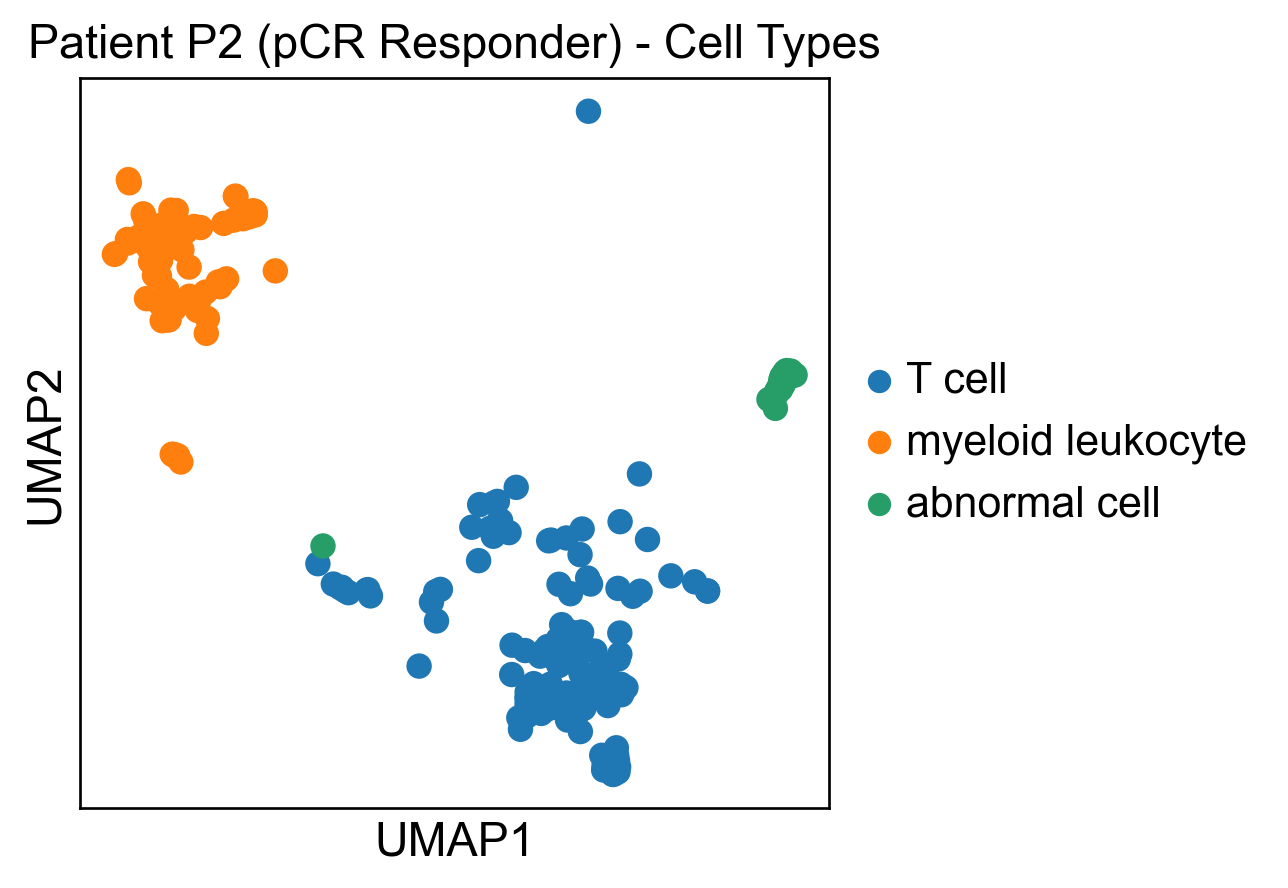

In [14]:
import scanpy as sc
# set scanpy figure parameters for clean, publication-ready plots
sc.set_figure_params(dpi=120, frameon=True)
# plot UMAP colored by cell type
sc.pl.umap(patient_subset, color='cell_type', title='Patient P2 (pCR Responder) - Cell Types')

In [15]:
# look for patients with residual disease(Rd) status
print(adata.obs[adata.obs['pCR_status'] == 'RD']['donor_id'].value_counts().head(5))

donor_id
P45    8815
P98    7265
P56    7143
P85    6967
P46    6949
Name: count, dtype: int64


In [17]:
import numpy as np 
import scanpy as sc 
# find the row indices where the donor is patient P45
idx_p45 = np.where(adata.obs['donor_id'] == 'P45')[0]
# subset the data and load it into memory
p45_subset = adata[idx_p45].to_memory()
# print the summary
print("--- Patient P45 Summary---")
print(p45_subset)
#check cell type distribution for patient P45
print("\n--- Cell Types in Patient P45 (RD Non-Responder) ---")
print(p45_subset.obs['cell_type'].value_counts())

--- Patient P45 Summary---
AnnData object with n_obs × n_vars = 8815 × 32354
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'cell_state', 'pCR_status', 'cell_type_ontology_term_id', 'assay_ontology_term_id', 'development_stage_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'sex_ontology_term_id', 'tissue_ontology_term_id', 'disease_ontology_term_id', 'suspension_type', 'tissue_type', 'donor_id', 'is_primary_data', 'author_cell_type', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'vf_vst_counts_mean', 'vf_vst_counts_variance', 'vf_vst_counts_variance.expected', 'vf_vst_counts_variance.standardized', 'vf_vst_counts_variable', 'vf_vst_counts_rank', 'var.features', 'var.features.rank', 'gene_symbols', 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type'
    uns: 'citation', 'is_pre_analysis', 'organism', 'organism_ontology_term_i

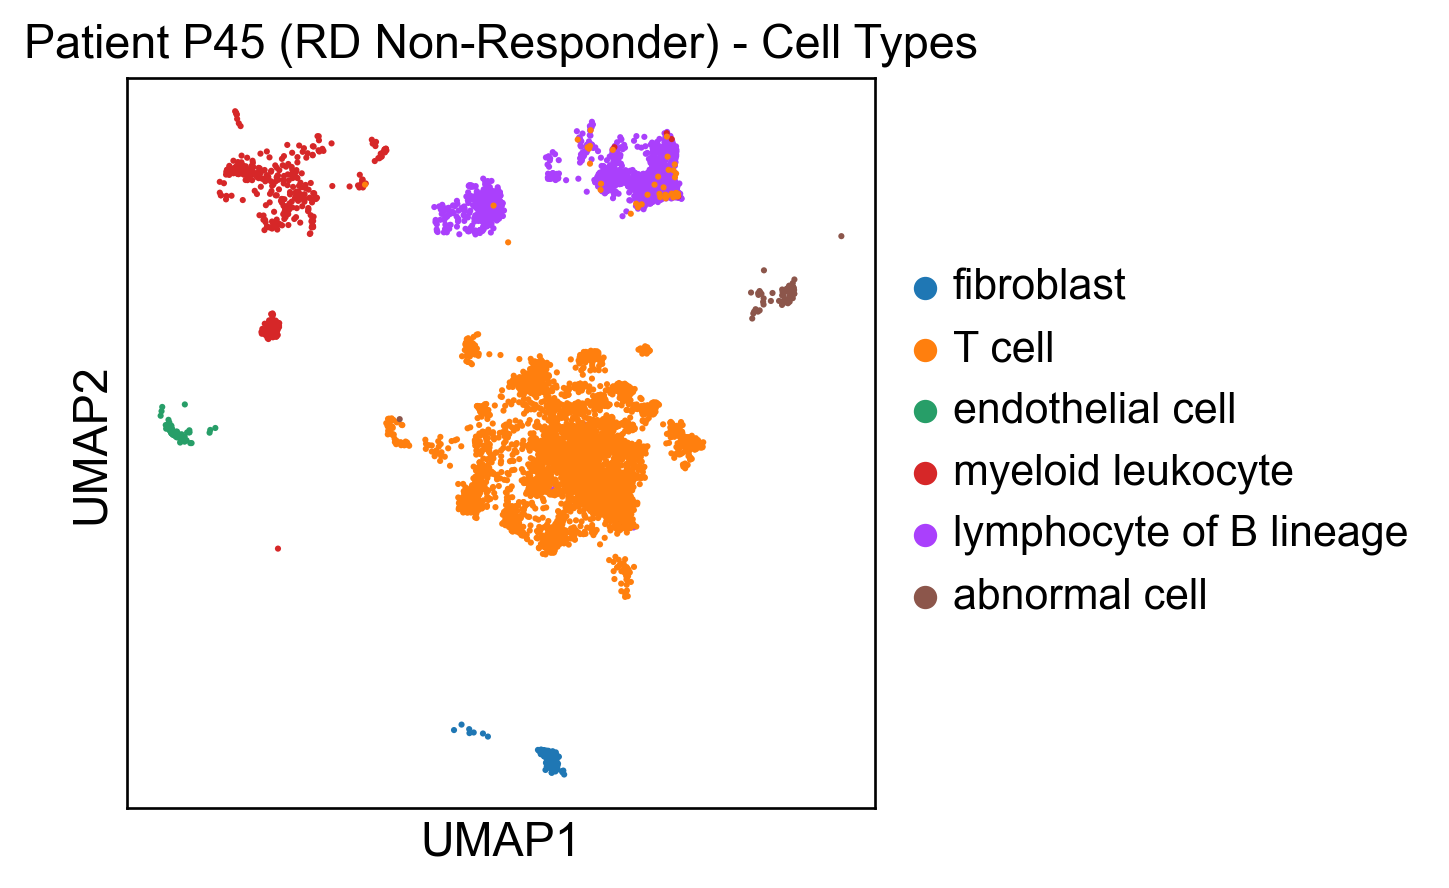

In [18]:
# plot UMAP colored by cell type for P atient P45
sc.pl.umap(p45_subset, color='cell_type', title='Patient P45 (RD Non-Responder) - Cell Types')

In [20]:
# save your patient subsets to disk so they are ready for tomorrow!
patient_subset.write(r"C:\sc_project\data\patient_p2_pcr.h5ad")
p45_subset.write(r"C:\sc_project\data\patient_p45_rd.h5ad")
print("Subsets saved successfully!")

Subsets saved successfully!


In [2]:
import scanpy as sc 
# load both pateints directly from disk
patient_subset = sc.read_h5ad(r"C:\sc_project\data\patient_p2_pcr.h5ad")
p45_subset = sc.read_h5ad(r"C:\sc_project\data\patient_p45_rd.h5ad")
print("Both patient datasets loaded instantly and ready to go!")

Both patient datasets loaded instantly and ready to go!


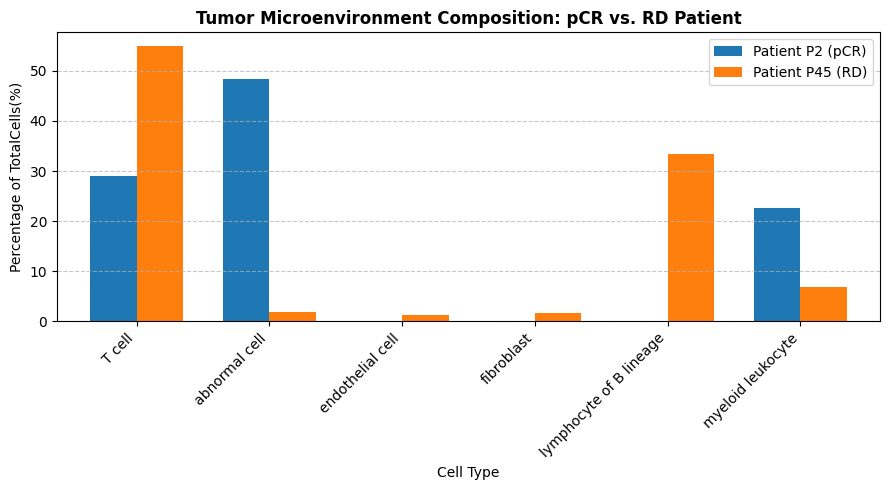

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
# calculate normalized proportions for each patient
p2_props = patient_subset.obs['cell_type'].value_counts(normalize=True) * 100
p45_props = p45_subset.obs['cell_type'].value_counts(normalize=True) * 100
# combine into a single pandas dataframe
df_comp = pd.DataFrame({'Patient P2 (pCR)': p2_props, 'Patient P45 (RD)': p45_props}).fillna(0)
# plot grouped bar chart
ax = df_comp.plot(kind='bar', figsize=(9,5), width=0.7)
plt.title('Tumor Microenvironment Composition: pCR vs. RD Patient', fontsize=12, fontweight='bold')
plt.ylabel('Percentage of TotalCells(%)')
plt.xlabel('Cell Type')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [8]:
import scanpy as sc
# re-open the full atlas in backed mode(instantly load without crashing RAM)
adata = sc.read_h5ad(r"C:\sc_project\data\tnbc_sc_seq.h5ad", backed='r')
print("Full dataset re-loaded successfully in backed mode!")

Full dataset re-loaded successfully in backed mode!


In [11]:
import pandas as pd
from IPython.display import display
# 1. extract the metadata dataframe from adata(which holds all cell labels and patient IDs)
meta_df = adata.obs[['donor_id', 'cell_type', 'pCR_status']].copy()
# 2. compute cell type countsper donor(with observed=False to clear warnings)
donor_counts = meta_df.groupby(['donor_id', 'pCR_status', 'cell_type'], observed=False).size().reset_index(name='cell_count')
# 3. calculate total cells per donor to find percentages
donor_totals = meta_df.groupby('donor_id', observed=False).size().reset_index(name='total_cells')
donor_counts = donor_counts.merge(donor_totals, on='donor_id')
donor_counts['percentage'] = (donor_counts['cell_count'] / donor_counts['total_cells']) *100
# 4. view average proportions grouped by pCR status across all 101 patients
summary_table = donor_counts.groupby(['pCR_status', 'cell_type'], observed=False)['percentage'].mean().unstack().fillna(0)
print("--- Global Cohort Summary:pCR vs RD Cell Type Proportions (%) ---")
display(summary_table)

--- Global Cohort Summary:pCR vs RD Cell Type Proportions (%) ---


cell_type,fibroblast,T cell,endothelial cell,myeloid leukocyte,lymphocyte of B lineage,abnormal cell,perivascular cell
pCR_status,,,,,,,
pCR,0.693873,25.368973,0.449765,4.739703,5.446953,7.635384,0.219806
RD,1.254064,19.743748,0.514433,5.016424,3.980734,5.881046,0.243214
Excluded,1.443056,9.356777,0.356698,2.447948,1.391533,3.608548,0.207321


C:\Users\deept\AppData\Local\Temp\ipykernel_13772\1806836209.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='pCR_status', y='percentage', data=t_cell_df, palette='Set2', boxprops=dict(alpha=0.8))


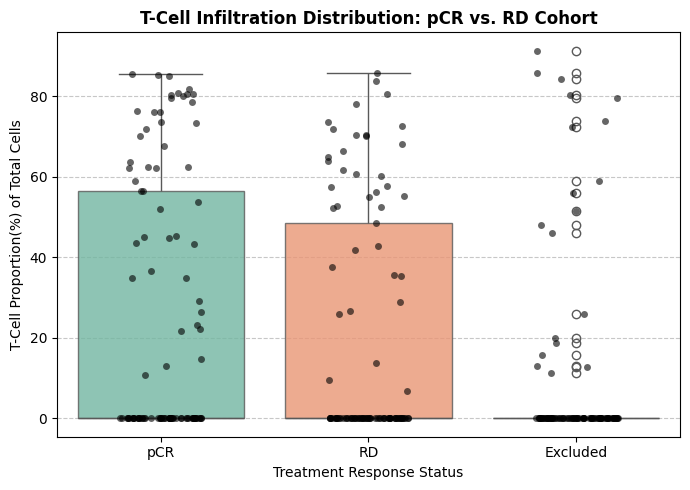

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt
# filter the donor counts specifically for T cells
t_cell_df = donor_counts[donor_counts['cell_type'] == 'T cell']
#set up the plot
plt.figure(figsize=(7, 5))
sns.boxplot(x='pCR_status', y='percentage', data=t_cell_df, palette='Set2', boxprops=dict(alpha=0.8))
sns.stripplot(x='pCR_status', y='percentage', data=t_cell_df, color='black', alpha=0.6, jitter=0.2, size=5)
# styling
plt.title('T-Cell Infiltration Distribution: pCR vs. RD Cohort', fontsize=12, fontweight='bold')
plt.ylabel('T-Cell Proportion(%) of Total Cells', fontsize=10)
plt.xlabel('Treatment Response Status', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

<Axes: xlabel='pCR_status', ylabel='percentage'>

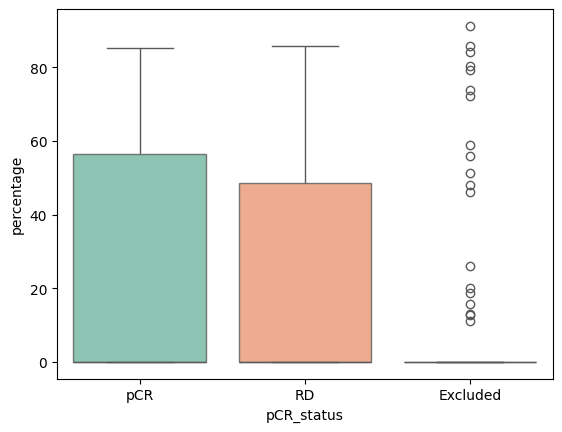

In [15]:
# updated boxplot command to keep your noebook pristine
sns.boxplot(x='pCR_status', y='percentage', hue='pCR_status', data=t_cell_df, palette='Set2', boxprops=dict(alpha=0.8), legend=False)

In [19]:
from scipy.stats import mannwhitneyu
# 1. isolate the T-cell percentages for pCR and RD Patients
pcr_tcells = t_cell_df[t_cell_df['pCR_status'] == 'pCR']['percentage']
rd_tcells = t_cell_df[t_cell_df['pCR_status'] == 'RD']['percentage']
#2. perform the Mann-Whitney U test (two-sided)
stat, p_value = mannwhitneyu(pcr_tcells, rd_tcells, alternative='two-sided')
#3. print out the results a clearly
print("--- Statistical Test: T-Cell Infiltration (pCR vs. RD) ---")
print(f"Mann-Whitney U Statistic: {stat:.2f}")
print(f"P-value: {p_value:.4f}")
if p_value < 0.05:
  print("Conclusion: Statistically significant difference in T-cell propertions between responders and non-responders!")
else:
   print("Conclusion: Trend observed, but not statistically significant at alpha = 0.05.")

--- Statistical Test: T-Cell Infiltration (pCR vs. RD) ---
Mann-Whitney U Statistic: 5599.00
P-value: 0.1775
Conclusion: Trend observed, but not statistically significant at alpha = 0.05.


In [20]:
# print all available metadata columns in your dataset
print("--- Available Metadata Columns in adata.obs ---")
for col in adata.obs.columns:
    print(f"- {col}")
# check unique values if a subtype or annotation column exists
# (Looking for common naming conventions like 'subtype', 'cell_subtype', 'cluster', etc.)
potential_cols = [c for c in adata.obs.columns if any(keyword in c.lower() for keyword in ['sub', 'detail', 'annot', 'cluster', 'state', 'type'])]
print("\n--- Potential Fine-Grained Annotation Columns ---")
print(potential_cols)

--- Available Metadata Columns in adata.obs ---
- orig.ident
- nCount_RNA
- nFeature_RNA
- cell_state
- pCR_status
- cell_type_ontology_term_id
- assay_ontology_term_id
- development_stage_ontology_term_id
- self_reported_ethnicity_ontology_term_id
- sex_ontology_term_id
- tissue_ontology_term_id
- disease_ontology_term_id
- suspension_type
- tissue_type
- donor_id
- is_primary_data
- author_cell_type
- cell_type
- assay
- disease
- sex
- tissue
- self_reported_ethnicity
- development_stage
- observation_joinid

--- Potential Fine-Grained Annotation Columns ---
['cell_state', 'cell_type_ontology_term_id', 'suspension_type', 'tissue_type', 'author_cell_type', 'cell_type']


In [21]:
# inspecct unique values in 'cell_state'
print("--- Unique Values in 'cell_state' ---")
print(adata.obs['cell_state'].dropna().unique())
# inspect unique values in 'author_cell_type'(showing first 25 to avoid clutter)
print("\n--- Sample Values in 'author_cell_type' ---")
author_types = adata.obs['author_cell_type'].dropna().unique()
print(author_types[:25] if len(author_types) > 25 else author_types)

--- Unique Values in 'cell_state' ---
['BN', 'BMEM-switched', 'plasma-lgG', 'plasma-lgA', 'BIFN', ..., 'VSMC-contra', 'peri-class', 'peri-immune', 'VSMC-synth', 'endo-prolif']
Length: 61
Categories (61, object): ['BIFN', 'BMEM-switched', 'BN', 'CAFs', ..., 'peri-class', 'peri-immune', 'plasma-lgA', 'plasma-lgG']

--- Sample Values in 'author_cell_type' ---
['B', 'Mye', 'T', 'Tumor', 'Endo', 'Fibro', 'Peri']
Categories (7, object): ['B', 'Endo', 'Fibro', 'Mye', 'Peri', 'T', 'Tumor']


In [22]:
# filter and display any cell states that contain 'T', 'CD', 'cytotoxic', exhaus', or 'immune'
t_states = [state for state in adata.obs['cell_state'].dropna().unique() if any( k in str(state).lower() for k in ['t', 'cd', 'tox', 'exh', 'act','imm', 'nk'])]
print("--- Potential T-Cell / Immune States in cell_state ---")
print(t_states)

--- Potential T-Cell / Immune States in cell_state ---
['BMEM-switched', 'cDC1', 'cDC2', 'mast', 'CD4-TREG', 'CD8-TEM', 'NK-CD16low', 'CD4-TN', 'CD4-TFH', 'CD8-TEXH', 'NK-CD16high', 'CD4-TIFN', 'T-prolif', 'GD-T', 'CD4-TCM', 'CD8-TIFN', 'CD8-TEFF', 'CD8-TRM', 'M10__EMT', 'M05__Interferon', 'M04__Stress', 'M13__StressER', 'M12__Cholestero', 'neutrophil', 'TEC', 'endo-arterial', 'fibro-matrix', 'fibro-prematrix', 'mac-lip-CD36', 'VSMC-contra', 'peri-immune', 'VSMC-synth']


In [28]:
import pandas as pd
from scipy.stats import mannwhitneyu
# define the key functional T-cell states we want to test
target_states = ['CD8-TEFF', 'CD8-TEXH', 'CD4-TREG', 'CD8-TRM', 'CD4-TCM', 'CD4-TFH']
# 1. Filter metadata for cells belonging to these states
sub_df = adata.obs[adata.obs['cell_state'].isin(target_states)].copy()
# 2. compute cell counts per donor and state 
state_counts = sub_df.groupby(['donor_id', 'pCR_status', 'cell_state'], observed=False).size().reset_index(name='cell_count')
donor_totals = adata.obs.groupby('donor_id', observed=False).size().reset_index(name='total_cells')
state_counts = state_counts.merge(donor_totals, on='donor_id')
state_counts['percentage'] =(state_counts['cell_count'] / state_counts['total_cells']) * 100
# 3. run Mann-Whitney U test for eachfunctional state
print("--- Fine-Grained T-Cell State Analysis:pCR vs. RD ---")
for state in target_states:
    pcr_vals = state_counts[(state_counts['cell_state'] == state) & (state_counts['pCR_status'] == 'pCR')]['percentage']
    rd_vals = state_counts[(state_counts['cell_state'] == state) & (state_counts['pCR_status'] == 'RD')]['percentage']
    if len(pcr_vals) > 0 and len(rd_vals) > 0:
     stat, p_val = mannwhitneyu(pcr_vals, rd_vals, alternative='two-sided')
     sig_marker = "SIGNIFICANT!" if p_val < 0.05 else""
    print(f"state: {state:<12} | p-value: {p_val:.4f} {sig_marker}")

--- Fine-Grained T-Cell State Analysis:pCR vs. RD ---
state: CD8-TEFF     | p-value: 0.2895 
state: CD8-TEXH     | p-value: 0.0583 
state: CD4-TREG     | p-value: 0.3086 
state: CD8-TRM      | p-value: 0.7977 
state: CD4-TCM      | p-value: 0.6316 
state: CD4-TFH      | p-value: 0.0958 
